# Ok-k-mer

Use python310 conda environment

## Imports

In [1]:
import os
# from random import randint
import multiprocessing as mp
from random import sample
from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40

In [2]:
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [3]:
import warnings
warnings.filterwarnings("ignore")


In [4]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Helper functions

In [5]:
def yield_file_lines(path):
    ''' Read file from path line-by-line. '''
    with open(path, 'r') as in_file:
        for line in in_file:
            yield line.strip()

In [6]:
def calc_corr(l1, l2, pearson=False, prnt=False):
    if pearson:
        corr, pval = pearsonr(l1, l2)
    else:
        corr, pval = spearmanr(l1, l2)
    if prnt:
        print("Correlation coefficient:", corr)
        print("p-value:", pval)
    return corr, pval

In [7]:
def dist_tree_calc(filename1):
    ''' Calculate tree distance. '''
    tree1= Tree(filename1,format=1)
    # print('Tree from', filename1, 'len:', len(tree1))
    dist_tree={}
    samples = [i.name for i in tree1.get_leaves()]
    num_sample = len(samples)
    for i in range(num_sample):
        tax_i = samples[i]
        for j in range(i+1,num_sample):
            tax_j = samples[j]
            dist_tree[(min(tax_i, tax_j)+".fa", max(tax_i, tax_j)+".fa")] = tree1.get_distance(tax_i, tax_j, topology_only=False)
    # print('num samples:', num_sample)
    # print('xxx:', num_sample * (num_sample-1)/2)
    # print('tree len:', len(dist_tree))
    return dist_tree


In [8]:
def make_tree_dict(tree_path):
    """
    Given a path to a Newick tree file, return a symmetric dictionary of distances between all pairs of taxa names
    (with or without '.fa' extension).

    Parameters:
        tree_path (str): Path to the Newick tree file.

    Returns:
        dict: A dictionary of dictionaries: { taxon_name: { other_taxon: distance, ... }, ... }
    """
    dist_tree = dist_tree_calc(tree_path)

    names = set()
    processed_pairs = []
    for (g1, g2), dist in dist_tree.items():
        g1_clean = g1.rstrip('.fa')
        g2_clean = g2.rstrip('.fa')
        names.add(g1_clean)
        names.add(g2_clean)
        processed_pairs.append((g1_clean, g2_clean, float(dist)))

    tree_dict = {name: {other: 0.0 for other in names} for name in names}
    for g1, g2, d in processed_pairs:
        tree_dict[g1][g2] = d
        tree_dict[g2][g1] = d  # Ensure symmetry

    return tree_dict


In [9]:

def get_random_samples(sample_names, sample_fraction=0.1, seed=None):
    '''
    # Example usage:
    cyano_random_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)
    '''
    if seed is not None:
        set_seed(seed)
    num_samples = max(1, int(len(sample_names) * sample_fraction))
    random_samples = sample(sample_names, num_samples)
    return random_samples



In [10]:
def parse_dashing_dfs(dir_path):
    """
    Parses all distance_* files in the given directory into a dictionary of pandas DataFrames.
    Each DataFrame skips the first line, assumes tab-separation and adjusts indices and columns as expected.

    Args:
        dir_path (str): Path to the directory containing distance_* files.

    Returns:
        dict: Dictionary mapping filename to corresponding DataFrame.
    """

    # Get list of files in directory that start with 'distance_'
    files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f)) and f.startswith('distance_')]

    # Create a dictionary to store dataframes
    dashing_dfs = {}

    # Read each file into a dataframe, skipping first line
    for file in files:
        file_path = os.path.join(dir_path, file)
        try:
            # Skip first line and read tab-separated data
            df = pd.read_csv(file_path, sep='\t', header=None, skiprows=1)
            df.index = df.iloc[:, 0].str.replace('genomes_ncbi/', '')
            df = df.iloc[:, 1:]
            df.columns = df.index
            dashing_dfs[file] = df
            # print(f"Successfully read {file}")
        except Exception as e:
            print(f"Error reading {file}: {str(e)}")

    # Print summary of loaded dataframes
    print(f"\nLoaded {len(dashing_dfs)} files")
    for file, df in dashing_dfs.items():
        print(f"{file}: {df.shape}")
    return dashing_dfs

In [11]:
def build_merged_df(tree_dict, dashing_dfs):
    """
    Build merged dataframe for all genome pairs among `genomes`,
    including tree distances and distances for each k from `dashing_dfs`.

    Parameters:
    -----------
    tree_dict : dict
        Nested dictionary of tree-based distances; tree_dict[g1][g2] gives distance.
    dashing_dfs : dict
        Mapping from dashing file name to pairwise distance DataFrame.

    Returns:
    --------
    merged_df : pd.DataFrame
        DataFrame indexed by sorted genome pairs, with metadata and k-mer distances.
    """

    genomes = sorted(tree_dict.keys())

    # Create all pairs of genomes (upper triangle only, sorted lexicographically)
    pairs = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            pair = '_'.join(sorted([genomes[i], genomes[j]]))
            pairs.append(pair)

    # Initialize dataframe with pairs as index
    merged_df = pd.DataFrame(index=pairs)

    # Add metadata columns to merged_df
    genome_pairs = []
    genomes_1s = []
    genomes_2s = []
    tree_distances = []
    for index in merged_df.index:
        # Split the genome pair
        genome1 = "_".join(index.split("_", 2)[:2])
        genome2 = "_".join(index.split("_", 2)[2:])

        # Get distance from tree_dict
        genome_pairs.append(index)
        genomes_1s.append(genome1)
        genomes_2s.append(genome2)
        tree_distances.append(tree_dict[genome1][genome2])

    merged_df['genome_pair'] = genome_pairs
    merged_df['genome_1'] = genomes_1s
    merged_df['genome_2'] = genomes_2s
    merged_df['tree_distance'] = tree_distances

    print(f"Final dataframe shape: {merged_df.shape}")

    # For each k, add a column to merged_df with the pairwise distances
    for fname, df in dashing_dfs.items():
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        # Build a dictionary mapping sorted genome pair -> distance
        pair_to_dist = {}
        for i in range(len(df)):
            g1 = df.iloc[i].name
            for g2, d in dict(df.iloc[i]).items():
                if g1 == g2: continue
                pair = '_'.join(sorted([g1, g2]))
                pair_to_dist[pair] = d

        # Map the distances to the merged_df for this k
        colname = f'k{k_val}_distance'
        merged_df[colname] = merged_df.index.map(pair_to_dist.get)
        print(f"Added column '{colname}' to merged_df.")

    return merged_df

In [12]:
def process_data(tree_path, dashing_dir_path):
    tree_dict = make_tree_dict(tree_path)
    dashing_dfs = parse_dashing_dfs(dashing_dir_path)
    merged_df = build_merged_df(tree_dict, dashing_dfs)
    return tree_dict, dashing_dfs, merged_df


## Process data

In [13]:
aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'

aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'

chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = process_data(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = process_data(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = process_data(caldisericia_tree_path, caldisericia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = process_data(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)


Loaded 60 files
distance_k42.txt: (288, 288)
distance_k10.txt: (288, 288)
distance_k54.txt: (288, 288)
distance_k58.txt: (288, 288)
distance_k39.txt: (288, 288)
distance_k57.txt: (288, 288)
distance_k26.txt: (288, 288)
distance_k34.txt: (288, 288)
distance_k11.txt: (288, 288)
distance_k22.txt: (288, 288)
distance_k7.txt: (288, 288)
distance_k45.txt: (288, 288)
distance_k61.txt: (288, 288)
distance_k14.txt: (288, 288)
distance_k52.txt: (288, 288)
distance_k59.txt: (288, 288)
distance_k18.txt: (288, 288)
distance_k38.txt: (288, 288)
distance_k31.txt: (288, 288)
distance_k41.txt: (288, 288)
distance_k55.txt: (288, 288)
distance_k60.txt: (288, 288)
distance_k64.txt: (288, 288)
distance_k33.txt: (288, 288)
distance_k12.txt: (288, 288)
distance_k30.txt: (288, 288)
distance_k15.txt: (288, 288)
distance_k56.txt: (288, 288)
distance_k44.txt: (288, 288)
distance_k37.txt: (288, 288)
distance_k36.txt: (288, 288)
distance_k63.txt: (288, 288)
distance_k51.txt: (288, 288)
distance_k21.txt: (288, 288

In [14]:
# Prepare a list of all available merged_dfs and their names
datasets = [
    # ("Aquificota", aquificota_merged_df),
    # ("Bacillales", bacillales_merged_df),
    # ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    # ("Cyano", cyano_merged_df),
    # ("Neisseriaceae", neisseriaceae_merged_df),
]


## Plot single k-mer heatmap

single-k: 6 0.05829258958237165 1.9052852538950723e-32


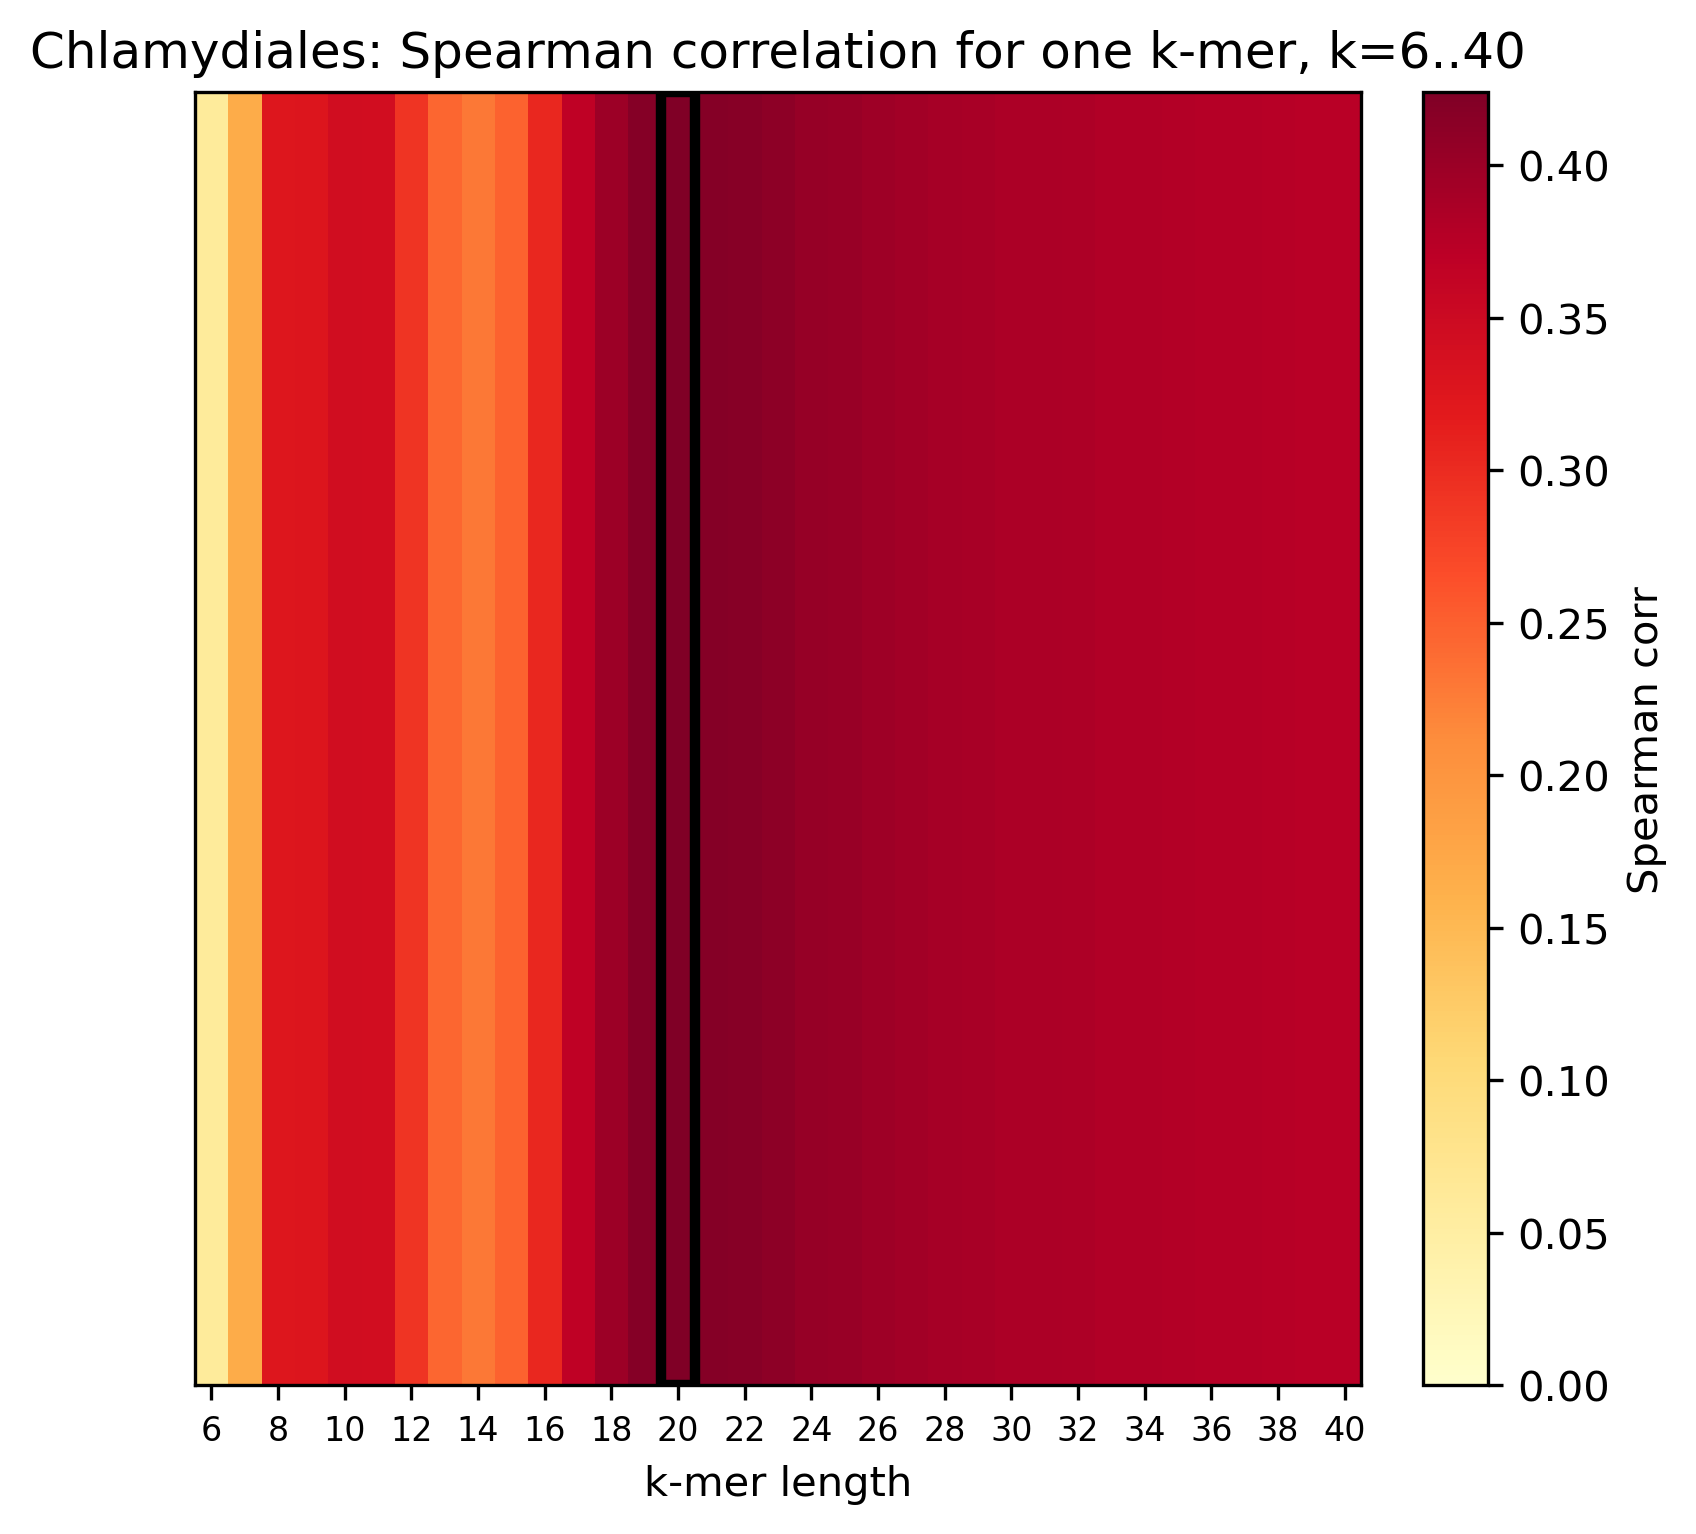

In [15]:
def plot_single_corr_colorbar(name, df, k_low=6, k_high=40):
    """Plot a single heatmap row with one colorbar for k-mer correlations."""
    arr = np.asarray(df)
    k_vals = arr[:, 0].astype(int)
    corr_vals = arr[:, 1].astype(float)
    keep = (k_vals >= k_low) & (k_vals <= k_high) # filter to k-mers between k_low and k_high
    k_vals = k_vals[keep]
    corr_vals = corr_vals[keep]
    heatmap = corr_vals[np.newaxis, :]  # shape (1, n_k)
    fig, ax = plt.subplots(1, 1, figsize=(5,5), constrained_layout=True) # square heatmap plot

    im = ax.imshow(
        heatmap,
        aspect="auto",
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        # vmin=np.nanmin(heatmap),
        # vmax=0.5252762634393853
    )

    xtick_pos = np.arange(0, len(k_vals), 2)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(k_vals[xtick_pos], fontsize=8)
    ax.set_yticks([])
    ax.set_ylabel("")

    ax.set_xlabel("k-mer length")
    # ax.set_title(f"{name}: Spearman correlation for k={k_low}..{k_high}")
    ax.set_title(f"Chlamydiales: Spearman correlation for one k-mer, k={k_low}..{k_high}")

    if np.any(np.isfinite(corr_vals)):
        best_x = int(np.nanargmax(corr_vals))
        rect = plt.Rectangle(
            (best_x - 0.5, -0.5),
            1,
            1,
            linewidth=2.5,
            edgecolor="black",
            facecolor="none",
        )
        ax.add_patch(rect)

    fig.colorbar(im, ax=ax, label="Spearman corr")
    plt.show()


def initial_corr(merged_df, iteration=0, k_low=5, k_high=32):
    ''' Find best single value k'''
    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))
    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
        results_matrix[i, :] = [k, -1*corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3])


results_matrix_init, (k, corr, pval) = initial_corr(chlamydia_merged_df, k_low=6, k_high=40)
print('single-k:', k, corr, pval)

# Usage
plot_single_corr_colorbar("Chlamydia", results_matrix_init, k_low=6, k_high=40)

## Full grid search: 3 k-mers, 2 weights

### Plot semi-fixed, grid scatter plots
k-sub-plots for each dataset, each subplot scatter plot of the k3 vs k2 values colored by correlation.

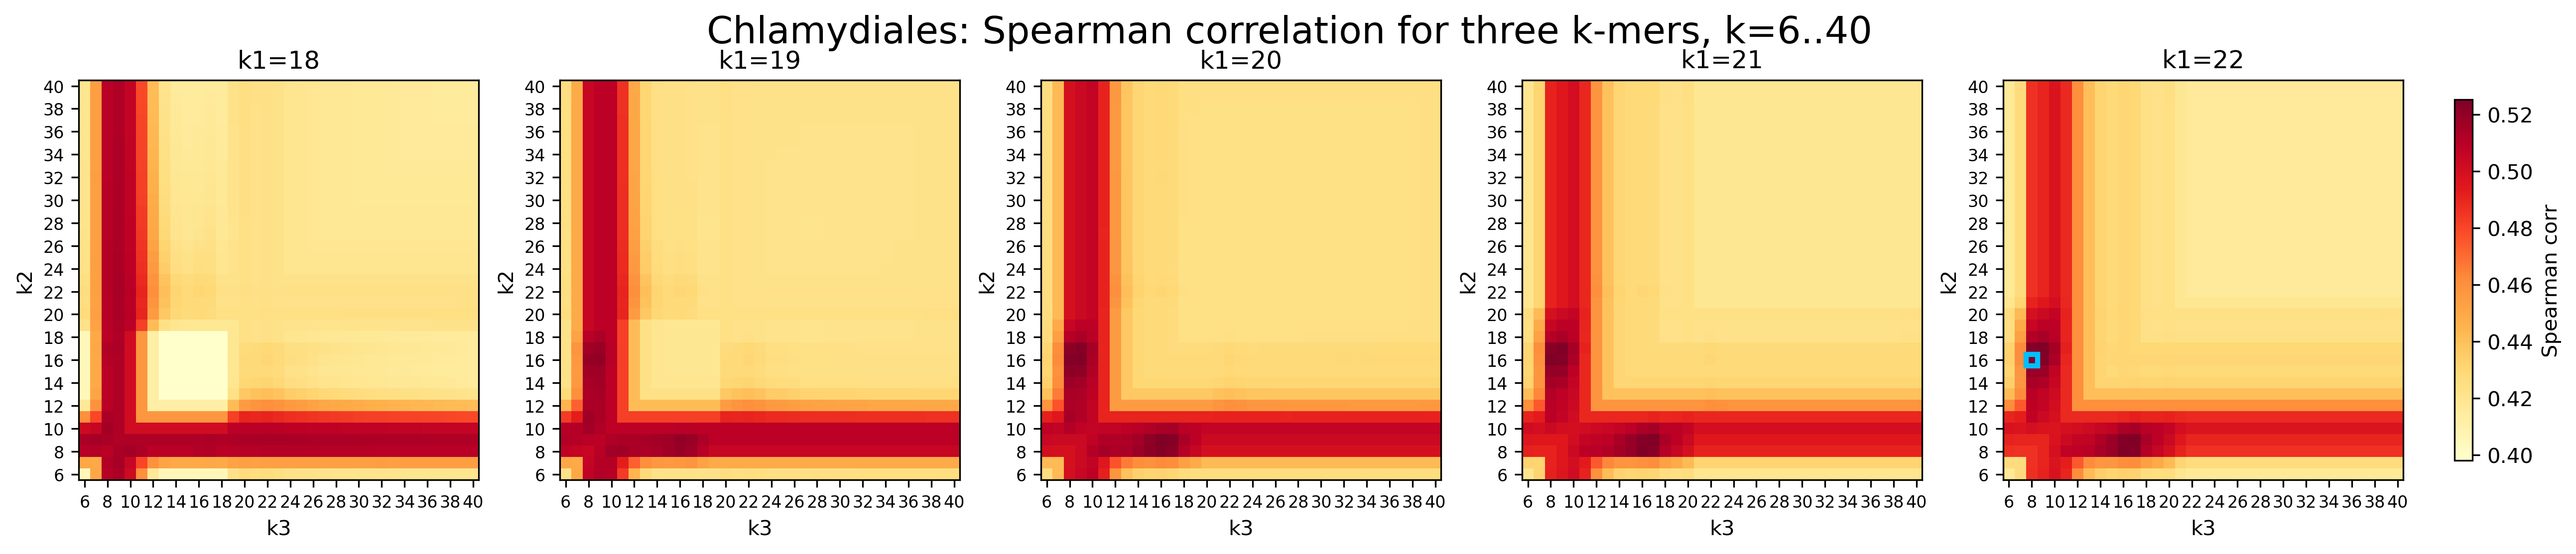

In [ ]:
# paths to datasets

# aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor.npy'
# bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor.npy'
# caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor.npy'
# cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor.npy'
# neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor.npy'

# aquificota_grid    = np.load(aquificota_grid_path)
# bacillales_grid    = np.load(bacillales_grid_path)
# caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
# cyano_grid         = np.load(cyano_grid_path)
# neisseriaceae_grid = np.load(neisseriaceae_grid_path)

## Take absolute value of all grids to ensure all values are positive
#aquificota_grid    = np.abs(aquificota_grid)
#bacillales_grid    = np.abs(bacillales_grid)
#caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = -1 * chlamydia_grid
#cyano_grid         = np.abs(cyano_grid)
#neisseriaceae_grid = np.abs(neisseriaceae_grid)


def plot_grid_heatmaps(name, grid_df, k, s, k_low, k_high):
    """
    Plot one heatmap per k1 in [k−s, …, k+s] (each 35×35, k2 × k3);
    collapse weight dims by min Spearman (matches grid objective), then negate
    so stronger associations plot as larger positive values (for YlOrRd).
    Only show every other tick for the x and y axes.
    Tick labels use a smaller font.
    In each subplot, color the best (largest) cell red.
    Across all subplots, color the overall best cell black.
    """
    planes = grid_df.max(axis=(3, 4))  # (n_k1, 35, 35); flip sign so min ρ → positive
    n_k1_full = planes.shape[0]
    half = (n_k1_full - 1) // 2
    if s > half:
        raise ValueError(f"s={s} exceeds k1 half-width {half} in grid")
    planes = planes[half - s : half + s + 1]
    n_panels = planes.shape[0]
    fig_w = 24 * n_panels / 7
    fig, axes = plt.subplots(1, n_panels, figsize=(fig_w, 3.5), constrained_layout=True, squeeze=False)
    axes = np.ravel(axes)
    pfin = planes[np.isfinite(planes)]
    vmin, vmax = float(np.min(pfin)), float(np.max(pfin))

    # k1 titles aligned with sliced panels (length must equal n_panels)
    k_subplot_labels = [k - s + i for i in range(n_panels)]
    k_axis_labels = list(range(k_low, k_high + 1))

    # Only select every other tick for the axes
    n_labels = len(k_axis_labels)
    xtick_positions = [i for i in range(n_labels) if i % 2 == 0]  # every other tick
    ytick_positions = [i for i in range(n_labels) if i % 2 == 0]
    xtick_labels = [k_axis_labels[i] for i in xtick_positions]
    ytick_labels = [k_axis_labels[i] for i in ytick_positions]

    # Overall best cell across all planes (largest after negation)
    global_max = np.nanmax(planes)
    g_indices = np.where(planes == global_max)
    if len(g_indices[0]) > 0:
        global_best_subplot = int(g_indices[0][0])
        global_best_y = int(g_indices[1][0])
        global_best_x = int(g_indices[2][0])
    else:
        global_best_subplot = global_best_y = global_best_x = None

    im = None
    tick_label_fontsize = 8  # Make tick labels smaller
    for i, ax in enumerate(axes):
        data = planes[i]
        im = ax.imshow(data, aspect="equal", origin="lower", vmin=vmin, vmax=vmax, cmap="YlOrRd")
        # im = ax.imshow(data, vmin=0, vmax=0.5252762634393853, origin="lower", aspect="equal", cmap="YlOrRd") # same min/max scale
        # print(vmin, vmax)

        ax.set_xlabel("k3")
        ax.set_ylabel("k2")
        ax.set_title(f"k1={k_subplot_labels[i]}")

        # Set x/y ticks and labels at every other tick, use smaller font
        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, fontsize=tick_label_fontsize)
        ax.set_yticks(ytick_positions)
        ax.set_yticklabels(ytick_labels, fontsize=tick_label_fontsize)

        # Highlight the best (largest) cell in the plane with a red rectangle or marker,
        # but only if there is at least one finite value.
        if np.any(np.isfinite(data)):
            max_val = np.nanmax(data)
            ys, xs = np.where(data == max_val)
            if len(ys) > 0:
                y, x = ys[0], xs[0]
                # If this cell is ALSO the global best, color it black. Otherwise, red.
                if i == global_best_subplot and y == global_best_y and x == global_best_x:
                    rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1,
                                        linewidth=2.5, edgecolor='#00BFFF', facecolor='none')
                    ax.add_patch(rect)
                # else:
                    # rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1,
                    #                     linewidth=2.5, edgecolor='red', facecolor='none')
                    # ax.add_patch(rect)
                # Optionally, overlay a dot at the center
                # if i == global_best_subplot and y == global_best_y and x == global_best_x:
                #     ax.plot(x, y, marker="o", color="black", markersize=6)
                # else:
                #     ax.plot(x, y, marker="o", color="red", markersize=6)

    fig.suptitle(f"Chlamydiales: Spearman correlation for three k-mers, k={k_low}..{k_high}", fontsize=18)

    # Move the colorbar (legend) more to the left by reducing the pad
    # You can use the ax argument as a list, but use the 'fraction' and 'pad' kwargs to move it left
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, location="right", label="Spearman corr", pad=0.02)
    plt.show()

# Usage example:
# plot_grid_heatmaps(name, grid_df, k, s, k_low, k_high)


grid_datasets_with_k_and_best = [
    # ("Aquificota", aquificota_grid, 20),
    # ("Bacillales", bacillales_grid, 24),
    # ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    # ("Cyano", cyano_grid, 20),
    # ("Neisseriaceae", neisseriaceae_grid, 19),
]

s = 2
k_low = 6
k_high = 40

for name, grid_df, k in grid_datasets_with_k_and_best:
    plot_grid_heatmaps(name, grid_df, k, s, k_low, k_high)




In [81]:

chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor.npy'
chlamydia_grid     = np.load(chlamydia_grid_path)
chlamydia_grid

array([[[[[-0.05829259, -0.05829259, -0.05829259, ..., -0.05829259,
           -0.05829259, -0.05829259],
          [-0.37627983, -0.37627983, -0.37627983, ..., -0.37627983,
           -0.37627983,         inf],
          [-0.37627983, -0.37627983, -0.37627983, ..., -0.37627983,
                   inf,         inf],
          ...,
          [-0.36936597, -0.36936583, -0.36936603, ...,         inf,
                   inf,         inf],
          [-0.36808566, -0.36808566,         inf, ...,         inf,
                   inf,         inf],
          [-0.3669359 ,         inf,         inf, ...,         inf,
                   inf,         inf]],

         [[-0.16656472, -0.1666252 , -0.1666252 , ..., -0.1666252 ,
           -0.1666252 , -0.05829259],
          [-0.42434008, -0.42461776, -0.42480513, ..., -0.43751883,
           -0.37627983,         inf],
          [-0.42510244, -0.42524461, -0.42534054, ..., -0.37627983,
                   inf,         inf],
          ...,
          [-0.

In [ ]:

# TODO; 4/14, check the min/max
    planes = grid_df.max(axis=(3, 4))  # (n_k1, 35, 35); flip sign so min ρ → positive
    n_k1_full = planes.shape[0]
    half = (n_k1_full - 1) // 2
    if s > half:
        raise ValueError(f"s={s} exceeds k1 half-width {half} in grid")
    planes = planes[half - s : half + s + 1]

In [ ]:
# 2D search

def run_full_grid_corr(merged_df, k_low=5, k_high=32, w_low=0, w_high=1, w_step=0.05):
    ''' Full grid search with all degrees of freedom: k1 low-> high, k2 low -> high, with all weights. '''
    ws = np.round(np.arange(w_low, w_high, w_step), 3)
    num_ws = len(ws)
    ks = list(range(k_low, k_high + 1))
    num_ks = len(ks)

    results_matrix = np.zeros((num_ks, num_ks, num_ws))

    for k1_idx, k1 in enumerate(ks):
        # print(k1)
        k1_rank = merged_df[f'k{k1}_distance'].rank()
        for k2_idx, k2 in enumerate(ks):
            k2_rank = merged_df[f'k{k2}_distance'].rank()
            for w_idx, w in enumerate(ws):
                avg_k1_k2_w_rank = w * k1_rank + (1 - w) * k2_rank   # weight the ranks by w and 1-w
                corr, pval = spearmanr(avg_k1_k2_w_rank, merged_df['tree_distance'])
                results_matrix[k1_idx, k2_idx, w_idx] = corr

    # find global min
    results_matrix = np.nan_to_num(results_matrix, nan=0.0)
    min_val = np.min(results_matrix)
    min_idx = np.unravel_index(np.argmin(results_matrix), results_matrix.shape)
    k1_min, k2_min, w_min = ks[min_idx[0]], ks[min_idx[1]], ws[min_idx[2]]
    print(f"Grid Ks: {k1_min, k2_min} with weight {w_min}; corr: {min_val}")
    print(min_idx)
    return results_matrix, min_val, k1_min, k2_min, w_min, min_val


# Run full grid search
for name, merged_df in datasets:
    print(name)
    results_matrix, min_val, k1_min, k2_min, w_min, min_val = run_full_grid_corr(merged_df, k_low=6, k_high=40, w_low=0.05)
    # results_matrix, min_val, k1_min, k2_min, w_min, min_val = run_full_grid_corr(merged_df, k_low=6, k_high=40)
    print()

results_matrix = np.abs(results_matrix)


Chlamydia
Grid Ks: (9, 18) with weight 0.45; corr: -0.5132143691921338
(3, 12, 8)



(array([3]), array([12])) 0.5132143691921338


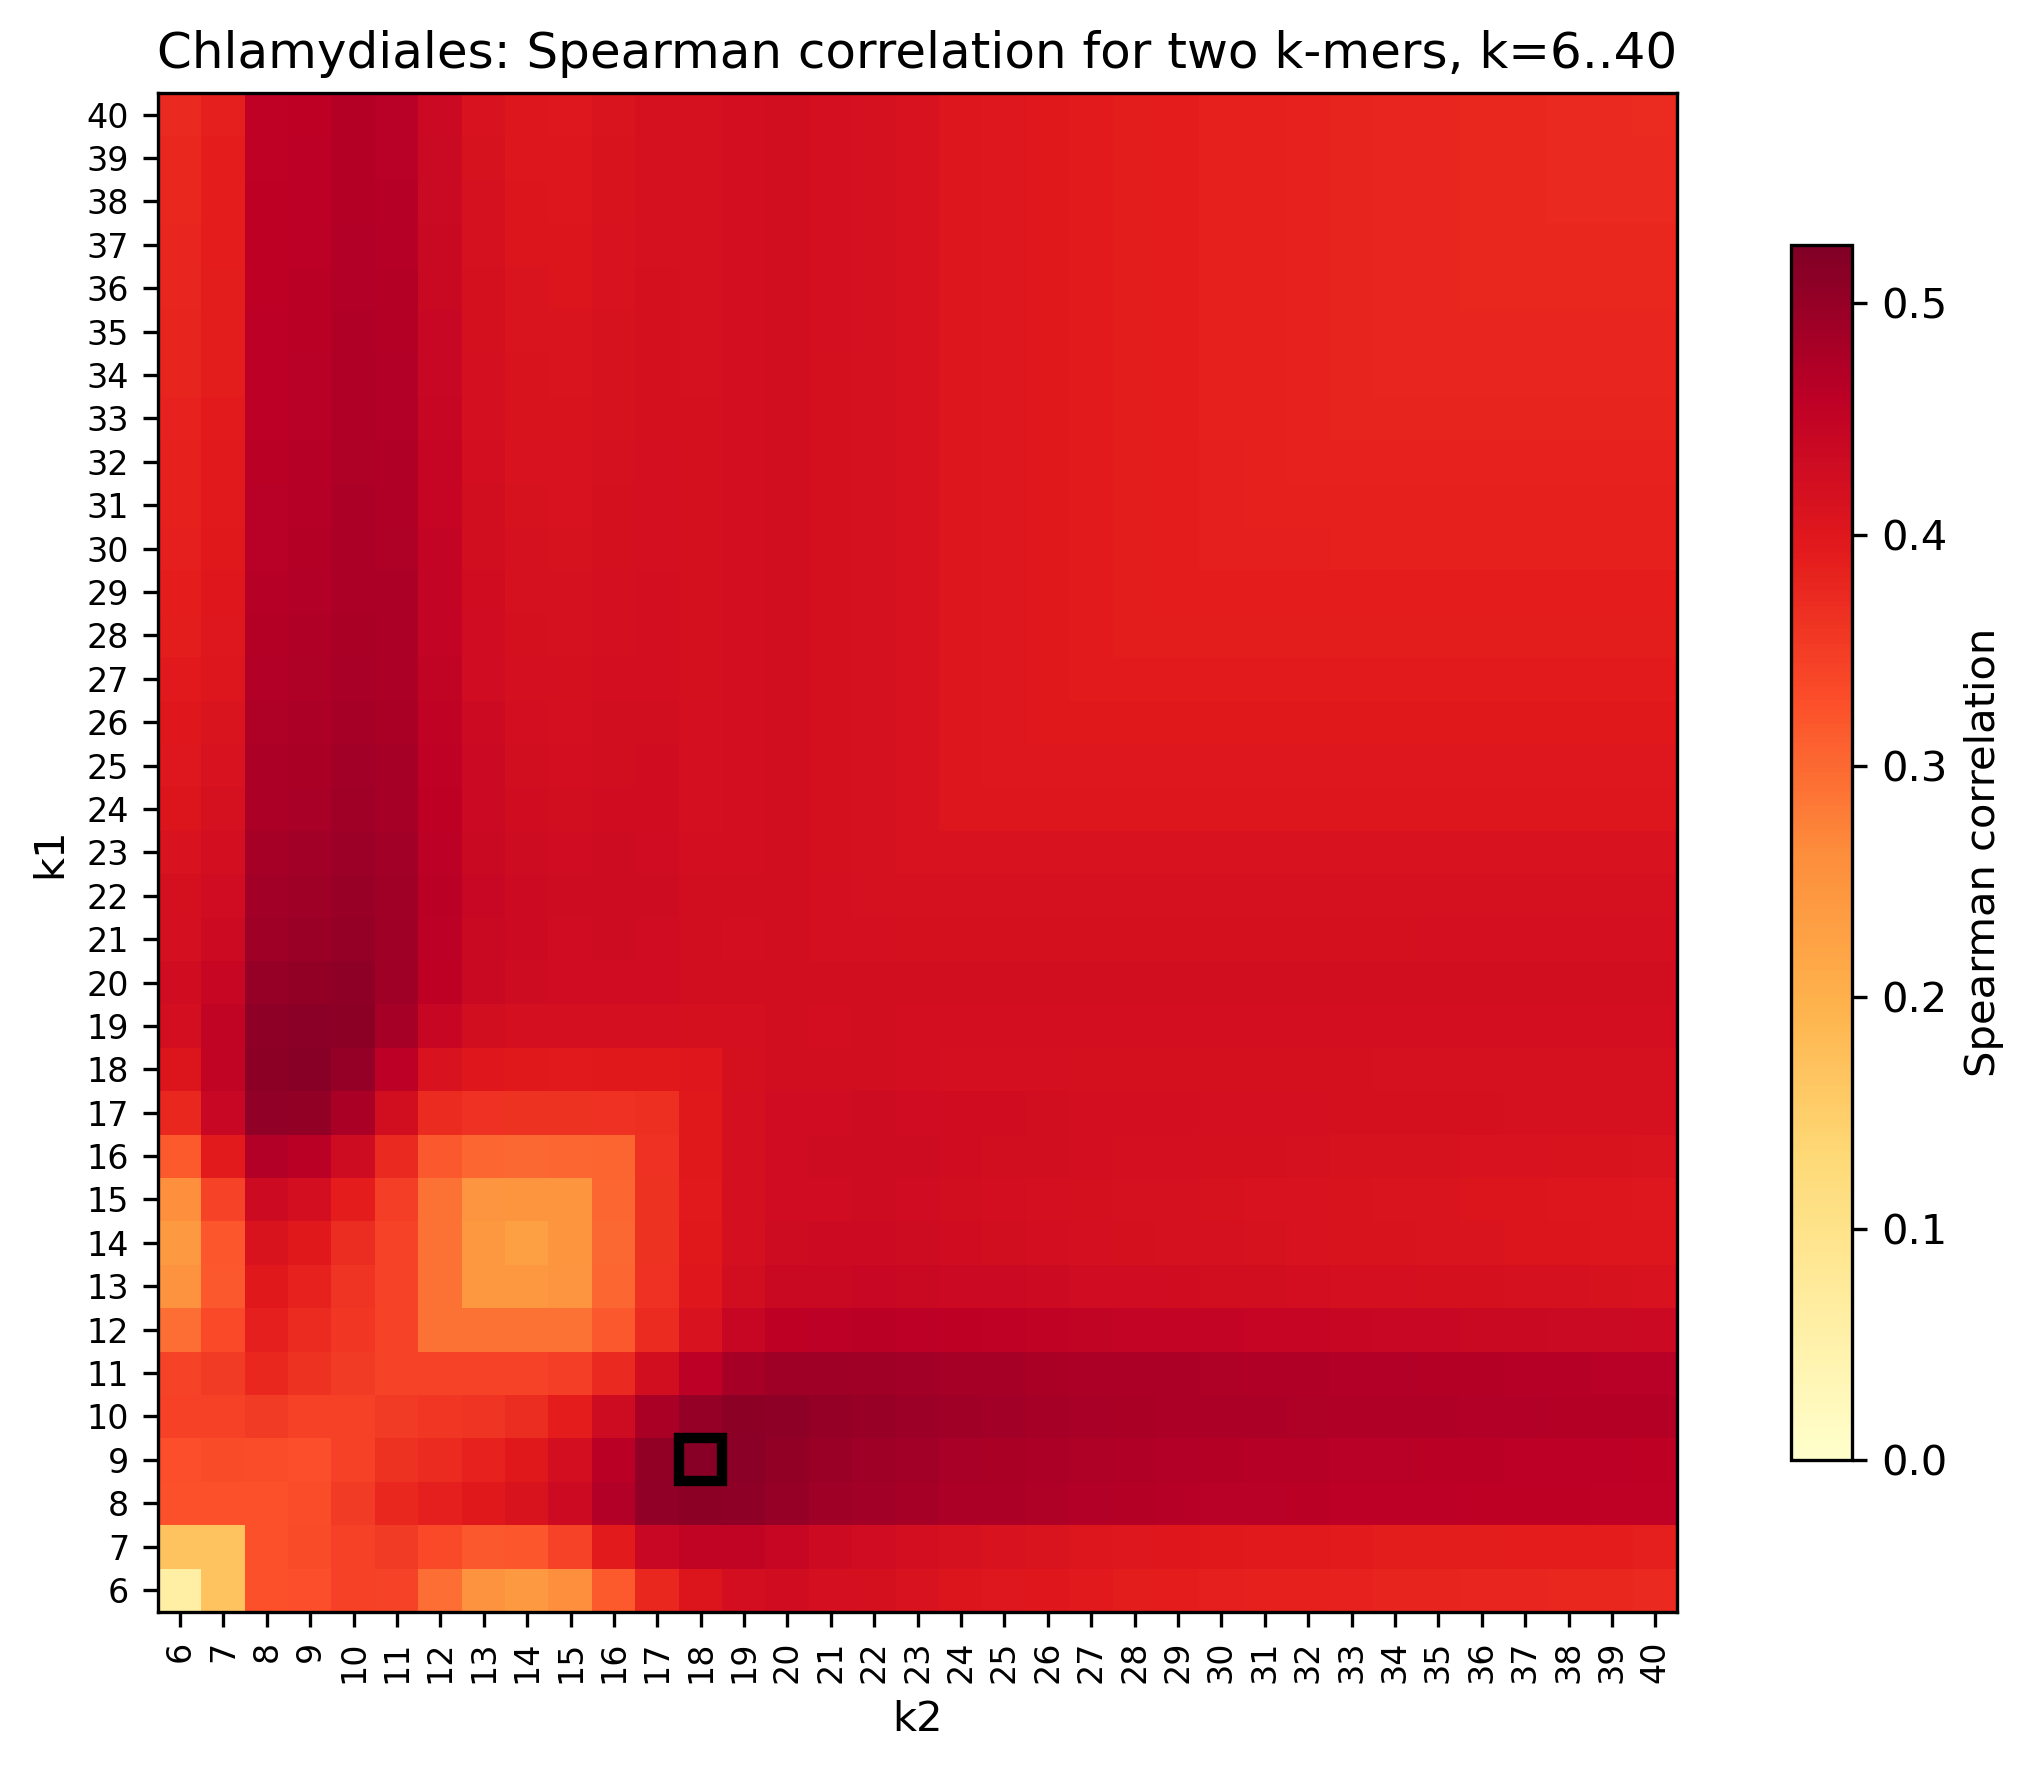

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_2d_heatmap_from_results_matrix(name, results_matrix, k_low, k_high):
    """
    Plot a 2D heatmap using only the first two dimensions (k1, k2) of results_matrix.
    Averages (or finds the min/max) over the remaining dimension (e.g., ws).
    Spearman correlation strength is shown; the axes cover all ks in the range.
    """

    # Average (or minimize/maximize as appropriate) over the third (ws) axis:
    # Here, let's use min as in grid objective.
    # aggregate_matrix = np.min(results_matrix, axis=2)  # shape [k1, k2]
    aggregate_matrix = np.max(results_matrix, axis=2)  # shape [k1, k2]

    ks = list(range(k_low, k_high + 1))
    n_ks = len(ks)
    fig, ax = plt.subplots(figsize=(8, 6))
    # im = ax.imshow(aggregate_matrix, origin="lower", aspect="equal", cmap="YlOrRd")
    im = ax.imshow(aggregate_matrix, vmin=0, vmax=0.5252762634393853, origin="lower", aspect="equal", cmap="YlOrRd")
    # im = ax.imshow(aggregate_matrix, vmin=0, origin="lower", aspect="equal", cmap="YlOrRd")


    # Label axes as k1 (y), k2 (x):
    ax.set_xlabel("k2")
    ax.set_ylabel("k1")
    # ax.set_title(f"{name}: Spearman correlation vs tree distance\n(k1, k2 grid, min over w)")
    ax.set_title(f"Chlamydiales: Spearman correlation for two k-mers, k={k_low}..{k_high}")
    # fig.suptitle(f"Chlamydiales: Spearman correlation for three k-mers, k={k_low}..{k_high}", fontsize=18)

    xticks = yticks = list(range(n_ks))
    ax.set_xticks(xticks)
    ax.set_xticklabels(ks, fontsize=8, rotation=90)
    ax.set_yticks(yticks)
    ax.set_yticklabels(ks, fontsize=8)

    # Optional: mark the globally min (best) cell
    max_val = np.nanmax(aggregate_matrix)
    min_indices = np.where(aggregate_matrix == max_val)
    print(min_indices, max_val)
    if len(min_indices[0]) > 0:
        y, x = min_indices[0][0], min_indices[1][0]
        ax.add_patch(plt.Rectangle((x-0.5, y-0.5), 1, 1, fill=False, edgecolor='black', lw=2.5))

    cbar = fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
    plt.tight_layout()
    plt.show()

# Example usage (replace with actual data as needed)
plot_2d_heatmap_from_results_matrix("Chlamydiales", results_matrix, k_low=6, k_high=40)


In [50]:
results_matrix.max(), np.nanmax(results_matrix)

(0.5132143691921338, 0.5132143691921338)

In [ ]:
results_matrix.shape

(35, 35, 19)

In [54]:
correction = 6
# max(results_matrix[21-correction][7-correction])
results_matrix[:][:]

# (3, 12, 8)


array([[[0.05829259, 0.05829259, 0.05829259, ..., 0.05829259,
         0.05829259, 0.05829259],
        [0.1666252 , 0.1666252 , 0.1666252 , ..., 0.1666252 ,
         0.1666252 , 0.1666252 ],
        [0.3252636 , 0.3252636 , 0.3252636 , ..., 0.3252636 ,
         0.3252636 , 0.3252636 ],
        ...,
        [0.37563581, 0.37591441, 0.37619542, ..., 0.37636054,
         0.37636054, 0.37636054],
        [0.3746329 , 0.37492159, 0.37520872, ..., 0.37547688,
         0.37547688, 0.37547688],
        [0.373444  , 0.37373828, 0.37403483, ..., 0.37440103,
         0.37440103, 0.37440103]],

       [[0.1666252 , 0.1666252 , 0.1666252 , ..., 0.1666252 ,
         0.1666252 , 0.1666252 ],
        [0.16656472, 0.16656472, 0.16656472, ..., 0.16656472,
         0.16656472, 0.16656472],
        [0.32531199, 0.32536504, 0.32548117, ..., 0.32540305,
         0.32553752, 0.32553749],
        ...,
        [0.3785145 , 0.38122493, 0.38356374, ..., 0.37454894,
         0.37365042, 0.37264406],
        [0.3

In [ ]:
(array([ 0, 14]), array([14,  0])) 0.4243600960389444
